# Satellite Patch Classification with Artificial Neural Networks (ANN)
## Sentinel-2: Urban vs Forest

**Laboratory report notebook** — this notebook implements the supervised-learning workflow, trains and compares five ANN configurations, and evaluates the selected model on a held-out test set.

> **Important:** the notebook does not invent satellite observations or performance scores. You must provide real Sentinel-2 image files and labels. All metrics and plots are generated when you run the notebook.

### Learning objective
Learn a function that maps a 200 × 200 pixel satellite patch to a binary label:

- `0` = urban
- `1` = forest

The notebook follows the same general workflow as the supplied diode ANN example: define input features and labels, build a `Sequential` model, compile it with a loss and optimizer, train with `fit()`, inspect the loss curve, and use the trained model for prediction. Unlike the diode regression example, this is a **classification** problem, so we use a sigmoid output and binary cross-entropy loss.

## 1. Function formulation and data representation

Let \(X\) be a multispectral satellite patch and \(y\) its class. The ANN learns

\[
f: X \longrightarrow y, \qquad y \in \{0,1\},
\]

where `0 = urban` and `1 = forest`.

Each source patch is 200 × 200 pixels and contains **four Sentinel-2 channels in a fixed order: B02, B03, B04, B08**. The notebook resizes each patch to 32 × 32 pixels before passing it to the Dense ANN. The model input therefore has shape `32 × 32 × 4`.

The four downloaded GeoTIFFs in one area folder are not four separate samples. They are four aligned spectral bands of one scene and are stacked into one four-channel image.

## 2. Prepare Sentinel-2 data

### Expected folder structure

Download four Sentinel-2 Level-2A areas (two urban and two forest for the initial dataset). For **each area**, download the raw analytical bands B02, B03, B04 and B08 as GeoTIFF. Keep all four bands from the same acquisition/area together.

Rename the downloaded files as shown below:

```text
Sentinel2_ANN_Project/
├── Sentinel2_ANN_Urban_Forest_Lab.ipynb
├── satellite_data/
│   ├── urban/
│   │   ├── urban_area_01/
│   │   │   ├── B02.tif
│   │   │   ├── B03.tif
│   │   │   ├── B04.tif
│   │   │   └── B08.tif
│   │   └── urban_area_02/
│   │       ├── B02.tif
│   │       ├── B03.tif
│   │       ├── B04.tif
│   │       └── B08.tif
│   └── forest/
│       ├── forest_area_01/
│       │   ├── B02.tif
│       │   ├── B03.tif
│       │   ├── B04.tif
│       │   └── B08.tif
│       └── forest_area_02/
│           ├── B02.tif
│           ├── B03.tif
│           ├── B04.tif
│           └── B08.tif
└── results/
    ├── models/
    ├── plots/
    └── metrics/
```

`True_color.tif` is optional and may be kept for visual inspection, but it is not used as a model input. Do not put it in place of the raw bands.

### Important dataset limitation

Four source areas (two per class) are enough to test the data-loading pipeline, but they are **not enough for a strong independent train/validation/test evaluation by source scene**. The recommended target is at least 3–5 independent areas per class, preferably more and from different locations. With only two areas per class, a held-out scene test is possible, but model selection and validation are less reliable. The notebook will warn about this limitation.

### Avoid data leakage

All patches from a source area must stay in the same data split. Never randomly distribute neighbouring patches from one GeoTIFF scene across train and test.

In [1]:
# Install dependencies if needed (uncomment in Google Colab)
# %pip install rasterio scikit-learn seaborn

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.4.6


### 2.1 Read and stack the four aligned bands, then extract 200 × 200 patches

The loader reads `B02.tif`, `B03.tif`, `B04.tif` and `B08.tif` from each area folder and stacks them in that exact order. It checks that all four rasters have matching dimensions and georeferencing. Patches with nodata or non-finite values are skipped.

In [6]:
from pathlib import Path
import numpy as np
import rasterio
from sklearn.model_selection import train_test_split

DATA_DIR = Path("satellite_data")
BAND_NAMES = ["B02", "B03", "B04", "B08"]
PATCH_SIZE = 200
PATCH_STRIDE = 200
MIN_VALID_FRACTION = 0.98


def read_area(area_dir):
    """Read one area folder and return H x W x 4 float32 array (B02,B03,B04,B08)."""

    area_dir = Path(area_dir)
    arrays, profiles = [], []

    for band in BAND_NAMES:

        # Obsługa rozszerzeń .tif oraz .tiff
        candidates = [
            area_dir / f"{band}.tif",
            area_dir / f"{band}.tiff"
        ]

        path = next((p for p in candidates if p.exists()), None)

        if path is None:
            raise FileNotFoundError(
                f"Missing required band {band} in {area_dir}. "
                "Expected .tif or .tiff"
            )

        with rasterio.open(path) as src:
            if src.count != 1:
                raise ValueError(
                    f"{path} should contain one band; found {src.count}."
                )

            arrays.append(src.read(1).astype(np.float32))
            profiles.append((
                src.width,
                src.height,
                src.transform,
                src.crs,
                src.nodata
            ))

    # Check whether all bands describe the same grid
    first = profiles[0]

    for band, prof in zip(BAND_NAMES[1:], profiles[1:]):
        if prof[:4] != first[:4]:
            raise ValueError(
                f"Grid mismatch in {area_dir}: {band} is not aligned with B02. "
                "Download the same AOI/product and resolution for all bands."
            )

    # Stack four spectral bands
    image = np.stack(arrays, axis=-1)

    # Create valid-data mask
    nodata_masks = []

    for arr, prof in zip(arrays, profiles):
        nodata = prof[4]
        mask = np.isfinite(arr)

        if nodata is not None:
            mask &= (arr != nodata)

        nodata_masks.append(mask)

    valid_mask = np.logical_and.reduce(nodata_masks)

    return image, valid_mask



def discover_areas():
    records = []

    for class_name, label in [("urban", 0), ("forest", 1)]:
        class_dir = DATA_DIR / class_name

        if not class_dir.exists():
            raise FileNotFoundError(f"Create folder: {class_dir}")

        for area_dir in sorted(class_dir.iterdir()):

            # Pomijamy pliki i foldery techniczne Jupyter
            if not area_dir.is_dir():
                continue

            if area_dir.name.startswith(".") or area_dir.name == "__pycache__":
                continue

            records.append((
                area_dir,
                label,
                f"{class_name}/{area_dir.name}"
            ))

    if not records:
        raise RuntimeError(
            "No area subfolders found. See the folder structure above."
        )

    return records



records = discover_areas()
print(f"Found {len(records)} source areas:")
for area_dir, label, area_id in records:
    print(f"  {area_id}: label={label}")

# Sentinel-2 L2A reflectance is commonly represented on a 0..10000 scale.
# Use one consistent scaling rule for every area; do not normalize each scene separately.
def scale_reflectance(image):
    image = image.astype(np.float32)
    finite = image[np.isfinite(image)]
    if finite.size == 0:
        raise ValueError("Image contains no finite pixel values.")
    # Copernicus analytical float exports can be either reflectance fractions or
    # scaled reflectance. This check handles the common 0..1 and 0..10000 cases.
    if np.nanpercentile(finite, 99) > 1.5:
        image = image / 10000.0
    return np.clip(image, 0.0, 1.0)

patches, labels, groups = [], [], []
for area_dir, label, area_id in records:
    image, valid_mask = read_area(area_dir)
    image = scale_reflectance(image)
    h, w, _ = image.shape
    area_count = 0
    for y0 in range(0, h - PATCH_SIZE + 1, PATCH_STRIDE):
        for x0 in range(0, w - PATCH_SIZE + 1, PATCH_STRIDE):
            mask_patch = valid_mask[y0:y0+PATCH_SIZE, x0:x0+PATCH_SIZE]
            if mask_patch.mean() < MIN_VALID_FRACTION:
                continue
            patch = image[y0:y0+PATCH_SIZE, x0:x0+PATCH_SIZE, :]
            if not np.isfinite(patch).all():
                continue
            patches.append(patch)
            labels.append(label)
            groups.append(area_id)
            area_count += 1
    print(f"{area_id}: {area_count} valid patches from {w}x{h} pixels")

X_raw = np.asarray(patches, dtype=np.float32)
y = np.asarray(labels, dtype=np.int32)
groups = np.asarray(groups)

if len(X_raw) == 0:
    raise RuntimeError("No patches extracted. Check image dimensions, nodata and patch size.")
print("Patch tensor:", X_raw.shape, "| labels:", y.shape)
print("Class counts:", {0: int((y == 0).sum()), 1: int((y == 1).sum())})

Found 4 source areas:
  urban/urban_area_01: label=0
  urban/urban_area_02: label=0
  forest/forest_area_01: label=1
  forest/forest_area_02: label=1
urban/urban_area_01: 84 valid patches from 2500x1549 pixels
urban/urban_area_02: 84 valid patches from 2500x1549 pixels
forest/forest_area_01: 84 valid patches from 2500x1549 pixels
forest/forest_area_02: 84 valid patches from 2500x1549 pixels
Patch tensor: (336, 200, 200, 4) | labels: (336,)
Class counts: {0: 168, 1: 168}


### 2.2 Split by source area and resize patches

To prevent leakage, the split is performed using source-area IDs, not individual patches. The code first tries to reserve one source area per class for testing. Remaining areas are divided into training and validation groups where possible.

With only two areas per class, the validation split cannot be fully independent of the training scenes. For a robust experiment, collect at least three independent areas per class (preferably 5 or more). If a split cannot be formed, add more source areas rather than randomly splitting neighbouring patches.

Held-out test areas: [np.str_('forest/forest_area_02'), np.str_('urban/urban_area_02')]
Train patches: 134 Validation patches: 34 Test patches: 168
NOTE: validation patches share source areas with training patches. Use more source areas for a fully scene-independent validation set.


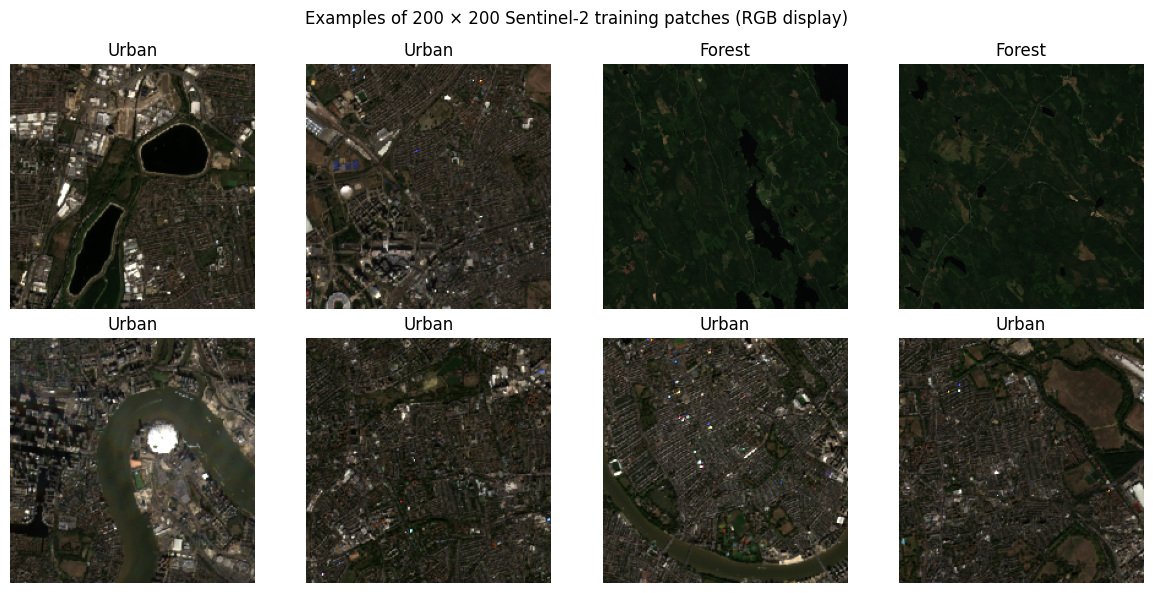

In [9]:
from sklearn.model_selection import GroupShuffleSplit

IMG_SIZE = (32, 32)

# Select one whole source area per class for the test set.
unique_by_class = {
    cls: sorted(set(groups[y == cls]))
    for cls in [0, 1]
}
if any(len(unique_by_class[c]) < 2 for c in [0, 1]):
    raise ValueError(
        "Need at least two independent source areas per class to create a scene-held-out test set. "
        "Add more area folders under satellite_data/urban and satellite_data/forest."
    )

test_area_ids = {unique_by_class[0][-1], unique_by_class[1][-1]}
test_mask = np.isin(groups, list(test_area_ids))
trainval_mask = ~test_mask

X_trainval_raw, y_trainval = X_raw[trainval_mask], y[trainval_mask]
groups_trainval = groups[trainval_mask]
X_test_raw, y_test = X_raw[test_mask], y[test_mask]

# Validation patches are drawn from the remaining training scenes.
# This is a patch-level validation split; test scenes remain completely unseen.
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_trainval_raw, y_trainval,
    test_size=0.20, random_state=SEED, stratify=y_trainval
)

print("Held-out test areas:", sorted(test_area_ids))
print("Train patches:", len(X_train_raw), "Validation patches:", len(X_val_raw),
      "Test patches:", len(X_test_raw))
print("NOTE: validation patches share source areas with training patches. "
      "Use more source areas for a fully scene-independent validation set.")

def resize_batch(images):
    resized = tf.image.resize(images, IMG_SIZE, method="bilinear")
    return resized.numpy().astype(np.float32)

X_train = resize_batch(X_train_raw)
X_val = resize_batch(X_val_raw)
X_test = resize_batch(X_test_raw)

class_names = {0: "Urban", 1: "Forest"}
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, idx in zip(axes.flat, range(min(8, len(X_train_raw)))):
    # Display B04, B03, B02 as an RGB-like composite (input order is B02,B03,B04,B08).
    rgb = X_train_raw[idx][..., [2, 1, 0]]
    ax.imshow(np.clip(rgb * 2.5, 0, 1))
    ax.set_title(class_names[int(y_train[idx])])
    ax.axis("off")
plt.suptitle("Examples of 200 × 200 Sentinel-2 training patches (RGB display)")
plt.tight_layout()
plt.show()

## 3. Baseline ANN architecture

The network is a fully connected (Dense) ANN:

1. Input: 32 × 32 × 4 values (B02, B03, B04, B08).
2. Flatten: converts the image tensor into a vector.
3. Hidden Dense layers: ReLU activation.
4. Output: one neuron with sigmoid activation, interpreted as the probability of the `Forest` class.

We use binary cross-entropy because there are two classes. Accuracy is reported alongside precision, recall and F1-score.

In [11]:
def build_ann(hidden_units=(64, 32), optimizer_name="adam", learning_rate=1e-3):
    model = tf.keras.Sequential(name="urban_forest_ann")
    model.add(tf.keras.layers.Input(shape=(*IMG_SIZE, 4)))
    model.add(tf.keras.layers.Flatten())
    for units in hidden_units:
        model.add(tf.keras.layers.Dense(units, activation="relu"))
        model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))

    if optimizer_name.lower() == "adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name.lower() == "sgd":
        optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    elif optimizer_name.lower() == "rmsprop":
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)
    else:
        raise ValueError("optimizer_name must be 'adam', 'sgd' or 'rmsprop'")

    model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["accuracy"])
    return model

baseline = build_ann((64, 32), "adam", 1e-3)
baseline.summary()

Model: "urban_forest_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,321 (1.01 MB)

 Trainable params: 264,321 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Five architecture/optimizer experiments

The five experiments vary hidden-layer width/depth, optimizer and learning rate. Each model uses the same train/validation/test split. Early stopping monitors validation loss and restores the best weights.

For a fair comparison, the test set is used **only after training** to calculate final metrics. If you tune the model after inspecting test results, create a new untouched test set.

In [12]:
EXPERIMENTS = [
    {"name": "ANN 1 - 32", "hidden": (32,), "optimizer": "adam", "lr": 1e-3},
    {"name": "ANN 2 - 64", "hidden": (64,), "optimizer": "adam", "lr": 1e-3},
    {"name": "ANN 3 - 64, 32", "hidden": (64, 32), "optimizer": "adam", "lr": 1e-3},
    {"name": "ANN 4 - 128, 64", "hidden": (128, 64), "optimizer": "adam", "lr": 1e-4},
    {"name": "ANN 5 - 128, 64, 32 SGD", "hidden": (128, 64, 32), "optimizer": "sgd", "lr": 1e-3},
]

EPOCHS = 30
BATCH_SIZE = 16
histories = {}
models = {}
rows = []

for config in EXPERIMENTS:
    print("\n" + "=" * 70)
    print("Training:", config["name"])
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_ann(
        hidden_units=config["hidden"],
        optimizer_name=config["optimizer"],
        learning_rate=config["lr"]
    )
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    # Validation metrics are used for model selection; test metrics are reported
    # for comparison and should not be used to tune the model.
    val_probabilities = model.predict(X_val, verbose=0).ravel()
    val_predictions = (val_probabilities >= 0.5).astype(int)
    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    rows.append({
        "Validation accuracy": accuracy_score(y_val, val_predictions),
        "Validation F1-score": f1_score(y_val, val_predictions, zero_division=0),
        "Model": config["name"],
        "Hidden layers": str(config["hidden"]),
        "Optimizer": config["optimizer"],
        "Learning rate": config["lr"],
        "Epochs trained": len(history.history["loss"]),
        "Test accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "Test loss": model.evaluate(X_test, y_test, verbose=0)[0]
    })
    histories[config["name"]] = history
    models[config["name"]] = model

results_df = pd.DataFrame(rows).sort_values("Validation F1-score", ascending=False)
display(results_df.round(4))


Training: ANN 1 - 32
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8060 - loss: 0.4972 - val_accuracy: 1.0000 - val_loss: 0.2458
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9925 - loss: 0.1811 - val_accuracy: 0.9706 - val_loss: 0.1126
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9925 - loss: 0.0786 - val_accuracy: 1.0000 - val_loss: 0.0598
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9925 - loss: 0.0577 - val_accuracy: 1.0000 - val_loss: 0.0430
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9851 - loss: 0.0479 - val_accuracy: 1.0000 - val_loss: 0.0338
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9925 - loss: 0.0334 - val_accuracy: 1.0000 - val_loss: 0.0281
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9925 - loss: 0.0281 - val_accuracy: 1.0000 - val_loss: 0.0252
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9851 - loss: 0.0349 - val_accuracy: 1.00


Training: ANN 4 - 128, 64
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.7463 - loss: 0.6428 - val_accuracy: 0.9706 - val_loss: 0.5695
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9403 - loss: 0.5356 - val_accuracy: 0.9706 - val_loss: 0.4623
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9925 - loss: 0.4115 - val_accuracy: 0.9706 - val_loss: 0.3636
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9851 - loss: 0.3336 - val_accuracy: 0.9706 - val_loss: 0.2813
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9925 - loss: 0.2407 - val_accuracy: 0.9706 - val_loss: 0.2160
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 0.1941 - val_accuracy: 0.9706 - val_loss: 0.1693
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9925 - loss: 0.1700 - val_accuracy: 0.9706 - val_loss: 0.1343
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9925 - loss: 0.1318 - val_accuracy:


Training: ANN 5 - 128, 64, 32 SGD
Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.4478 - loss: 0.6988 - val_accuracy: 0.5000 - val_loss: 0.6951
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5299 - loss: 0.6889 - val_accuracy: 0.5000 - val_loss: 0.6814
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5224 - loss: 0.6820 - val_accuracy: 0.5000 - val_loss: 0.6690
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5075 - loss: 0.6687 - val_accuracy: 0.5000 - val_loss: 0.6591
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5299 - loss: 0.6567 - val_accuracy: 0.5000 - val_loss: 0.6501
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6194 - loss: 0.6393 - val_accuracy: 0.5000 - val_loss: 0.6367
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6119 - loss: 0.6413 - val_accuracy: 0.6765 - val_loss: 0.6162
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7313 - loss: 0.6061 - val_a

,Validation accuracy,Validation F1-score,Model,Hidden layers,Optimizer,Learning rate,Epochs trained,Test accuracy,Precision,Recall,F1-score,Test loss
0,1.0000,1.0000,ANN 1 - 32,"(32,)",adam,0.0010,27,0.9643,0.9643,0.9643,0.9643,0.1193
1,1.0000,1.0000,ANN 2 - 64,"(64,)",adam,0.0010,30,0.9643,0.9643,0.9643,0.9643,0.1053
2,1.0000,1.0000,"ANN 3 - 64, 32","(64, 32)",adam,0.0010,19,0.9583,0.9639,0.9524,0.9581,0.1082
3,1.0000,1.0000,"ANN 4 - 128, 64","(128, 64)",adam,0.0001,30,0.9702,0.9647,0.9762,0.9704,0.0989
4,0.9706,0.9714,"ANN 5 - 128, 64, 32 SGD","(128, 64, 32)",sgd,0.0010,30,0.9762,0.9545,1.0000,0.9767,0.1717


## 5. Compare training curves

The training and validation loss curves help identify convergence and overfitting. A training loss that continues to decrease while validation loss increases can indicate overfitting.

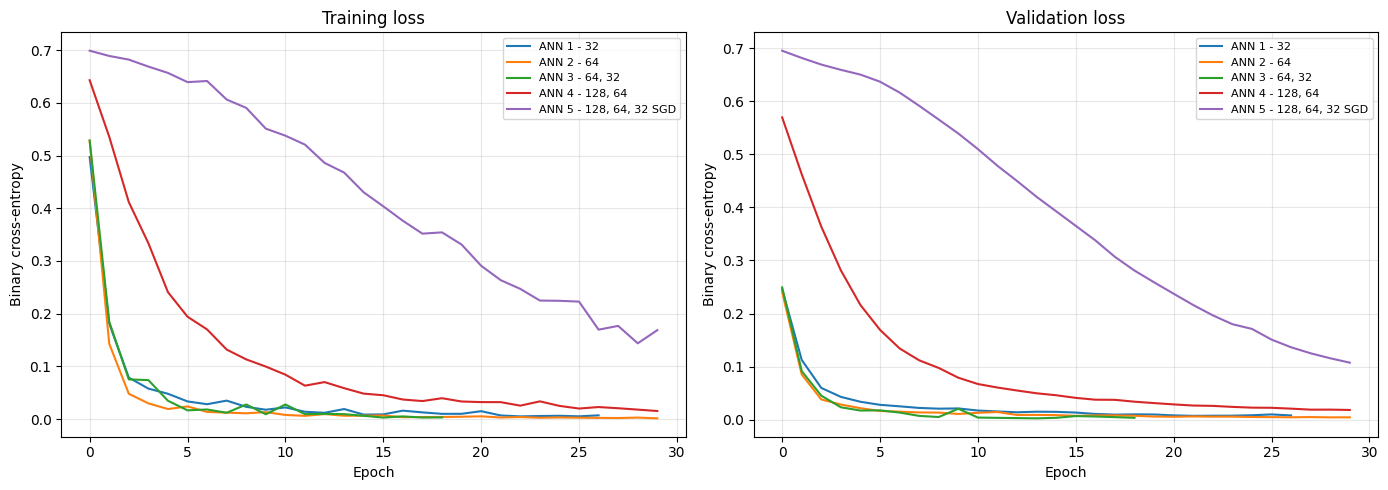

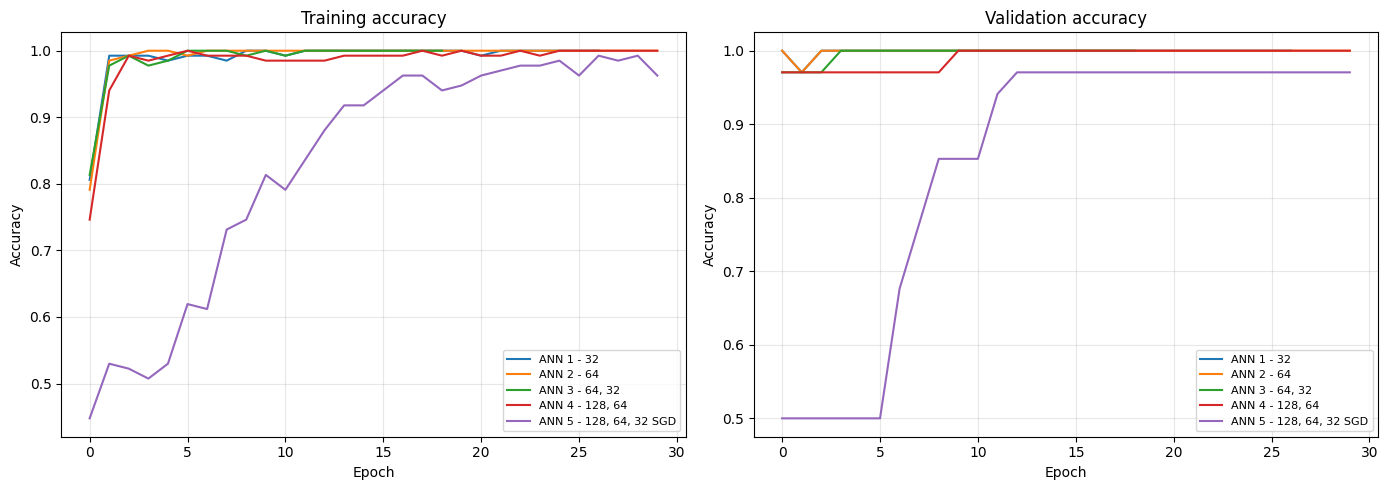

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in histories.items():
    axes[0].plot(history.history["loss"], label=name)
    axes[1].plot(history.history["val_loss"], label=name)

axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Binary cross-entropy")
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in histories.items():
    axes[0].plot(history.history["accuracy"], label=name)
    axes[1].plot(history.history["val_accuracy"], label=name)
axes[0].set_title("Training accuracy")
axes[1].set_title("Validation accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Final evaluation and confusion matrix

The five configurations are compared using the same held-out test set, and the table also includes validation metrics. The **validation F1-score** is used to select the model; test metrics are reported as the final comparison and should not be used to tune the model. In a formal final evaluation, keep the test set untouched until the architecture and hyperparameters have been selected.

,Validation accuracy,Validation F1-score,Model,Hidden layers,Optimizer,Learning rate,Epochs trained,Test accuracy,Precision,Recall,F1-score,Test loss
0,1.0000,1.0000,ANN 1 - 32,"(32,)",adam,0.0010,27,0.9643,0.9643,0.9643,0.9643,0.1193
1,1.0000,1.0000,ANN 2 - 64,"(64,)",adam,0.0010,30,0.9643,0.9643,0.9643,0.9643,0.1053
2,1.0000,1.0000,"ANN 3 - 64, 32","(64, 32)",adam,0.0010,19,0.9583,0.9639,0.9524,0.9581,0.1082
3,1.0000,1.0000,"ANN 4 - 128, 64","(128, 64)",adam,0.0001,30,0.9702,0.9647,0.9762,0.9704,0.0989
4,0.9706,0.9714,"ANN 5 - 128, 64, 32 SGD","(128, 64, 32)",sgd,0.0010,30,0.9762,0.9545,1.0000,0.9767,0.1717


Selected model: ANN 1 - 32
              precision    recall  f1-score   support

       Urban       0.96      0.96      0.96        84
      Forest       0.96      0.96      0.96        84

    accuracy                           0.96       168
   macro avg       0.96      0.96      0.96       168
weighted avg       0.96      0.96      0.96       168



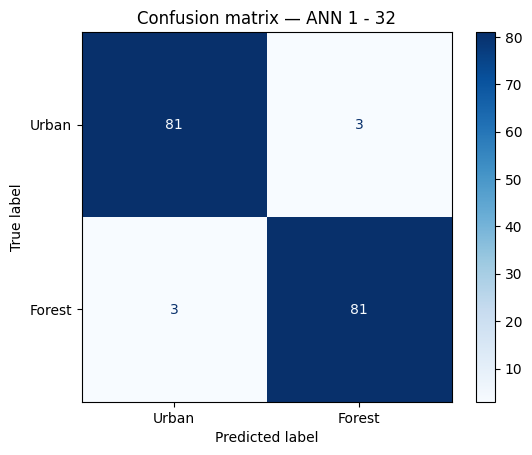

In [14]:
# Display test metrics for all five experiments
display(results_df.round(4))

# Confusion matrix and detailed classification report for the top-ranked model
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
best_probabilities = best_model.predict(X_test, verbose=0).ravel()
best_predictions = (best_probabilities >= 0.5).astype(int)

print("Selected model:", best_name)
print(classification_report(
    y_test, best_predictions,
    labels=[0, 1],
    target_names=["Urban", "Forest"],
    zero_division=0
))

cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=["Urban", "Forest"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix — {best_name}")
plt.show()

## 7. Example prediction on a new four-band patch

For a valid prediction, provide a 200 × 200 patch with the same four bands and the same order (B02, B03, B04, B08). The example below reads a folder containing `B02.tif`, `B03.tif`, `B04.tif` and `B08.tif`, extracts its top-left patch and applies the same reflectance scaling.

In [15]:
NEW_PATCH_DIR = Path("new_patch")  # folder containing B02.tif, B03.tif, B04.tif, B08.tif

if NEW_PATCH_DIR.exists():
    new_image, new_valid = read_area(NEW_PATCH_DIR)
    if new_image.shape[0] < PATCH_SIZE or new_image.shape[1] < PATCH_SIZE:
        raise ValueError(f"New scene must be at least {PATCH_SIZE}x{PATCH_SIZE} pixels.")
    new_patch = new_image[:PATCH_SIZE, :PATCH_SIZE, :]
    if not new_valid[:PATCH_SIZE, :PATCH_SIZE].all():
        raise ValueError("The selected new patch contains nodata pixels; choose another patch.")
    new_patch = scale_reflectance(new_patch)
    new_input = resize_batch(np.expand_dims(new_patch, axis=0))
    forest_probability = float(best_model.predict(new_input, verbose=0)[0, 0])
    predicted_label = int(forest_probability >= 0.5)
    print("Prediction:", class_names[predicted_label])
    print(f"Probability of forest: {forest_probability:.3f}")
    plt.imshow(np.clip(new_patch[..., [2, 1, 0]] * 2.5, 0, 1))
    plt.title(f"Predicted: {class_names[predicted_label]}")
    plt.axis("off")
    plt.show()
else:
    print("Optional: create 'new_patch/' with B02.tif, B03.tif, B04.tif and B08.tif.")

Optional: create 'new_patch/' with B02.tif, B03.tif, B04.tif and B08.tif.


## 8. Discussion and interpretation


Five different Artificial Neural Network configurations were trained and evaluated for Sentinel-2 satellite image classification. The objective was to distinguish between urban and forest areas using four spectral bands: B02 (Blue), B03 (Green), B04 (Red), and B08 (Near Infrared).

All five models achieved high classification performance. Models ANN 1–4 reached 100% validation accuracy, while ANN 5 achieved 97.06%. On the independent test set, accuracy ranged from 95.83% to 97.62%.

ANN 5, consisting of three hidden layers (128, 64, and 32 neurons) and using the SGD optimizer, achieved the highest test accuracy (97.62%) and F1-score (0.9767). However, ANN 1, with a single hidden layer containing 32 neurons, was selected based on validation performance and model simplicity. It achieved 96.43% test accuracy, precision, recall, and F1-score.

The learning curves show that ANN 1, ANN 2, and ANN 3 converged relatively quickly, with training and validation losses decreasing to very low values. ANN 4 also achieved excellent performance, although its convergence was slower. ANN 5 demonstrated slower learning, which is consistent with its use of the SGD optimizer and a more complex architecture.

The confusion matrix for ANN 1 showed 81 correctly classified urban patches and 81 correctly classified forest patches. Three urban patches were incorrectly classified as forest, and three forest patches were incorrectly classified as urban. Therefore, the model correctly classified 162 out of 168 test samples.

The results indicate that even a relatively simple ANN can achieve high accuracy in distinguishing urban and forest areas using Sentinel-2 spectral information. The experiment also demonstrates that increasing the number of hidden layers and neurons does not necessarily improve classification performance.

One important limitation is the relatively small number of independent source areas. Furthermore, training and validation patches originated from the same source scenes. Consequently, validation results may be optimistic. Additional independent satellite scenes would be required to assess the model's generalization more reliably.